In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_excel("Practical_Dataset for ML.xlsx", sheet_name="Data")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3000, 17)


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


In [3]:
df.isnull().sum()

house_id                       0
size_sqm                       0
num_bedrooms                   0
num_bathrooms                  0
floor_level                    0
age_years                      0
renovated                      0
distance_to_bole_km            0
distance_to_main_road_m        0
has_garage                     0
parking_spaces                 0
has_garden                     0
security_service               0
water_supply_hours_per_day    63
school_rating                 53
days_on_market                 0
price_etb                      0
dtype: int64

In [4]:
features = [
    col for col in df.columns
    if col not in ["house_id", "price_etb"]
]

X = df[features]
y = df["price_etb"]

print("Features:")
print(features)

Features:
['size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market']


In [5]:
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

X_imputed.head()

,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market
0,84.8,3.0,3.0,0.0,12.0,1.0,9.54,195.0,1.0,1.0,0.0,1.0,18.1,4.2,56.0
1,142.1,4.0,3.0,12.0,21.0,0.0,2.03,119.0,1.0,3.0,0.0,1.0,9.1,6.1,19.0
2,110.3,3.0,3.0,0.0,6.0,0.0,6.96,260.0,0.0,0.0,1.0,0.0,24.0,6.7,19.0
3,32.0,1.0,1.0,11.0,5.0,0.0,7.28,157.0,0.0,0.0,0.0,0.0,13.5,4.6,74.0
4,61.9,2.0,1.0,6.0,13.0,0.0,10.04,153.0,1.0,2.0,0.0,1.0,18.1,7.5,12.0


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed,
    y,
    test_size=0.2,
    random_state=42
)

In [7]:
mlr_model = LinearRegression()

mlr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ 48021.12,-59780.9 , 1723.68,..., 7804.61, 9895.18, 402.79]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['size_sqm','num_bedrooms','num_bathrooms',..., 'water_supply_hours_per_day','school_rating','days_on_market']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.731e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)


In [8]:
y_pred = mlr_model.predict(X_test)

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1235502.468861235
MSE: 4450927352895.082
RMSE: 2109722.1032389747
R²: 0.8336061121881947


In [10]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": mlr_model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

coefficients

,Feature,Coefficient
5,renovated,564057.873771
11,security_service,306556.219705
6,distance_to_bole_km,-278239.422814
10,has_garden,231597.880239
9,parking_spaces,100798.786865
1,num_bedrooms,-59780.896770
4,age_years,-51220.487039
0,size_sqm,48021.123445
8,has_garage,41005.744741
3,floor_level,-11112.519624


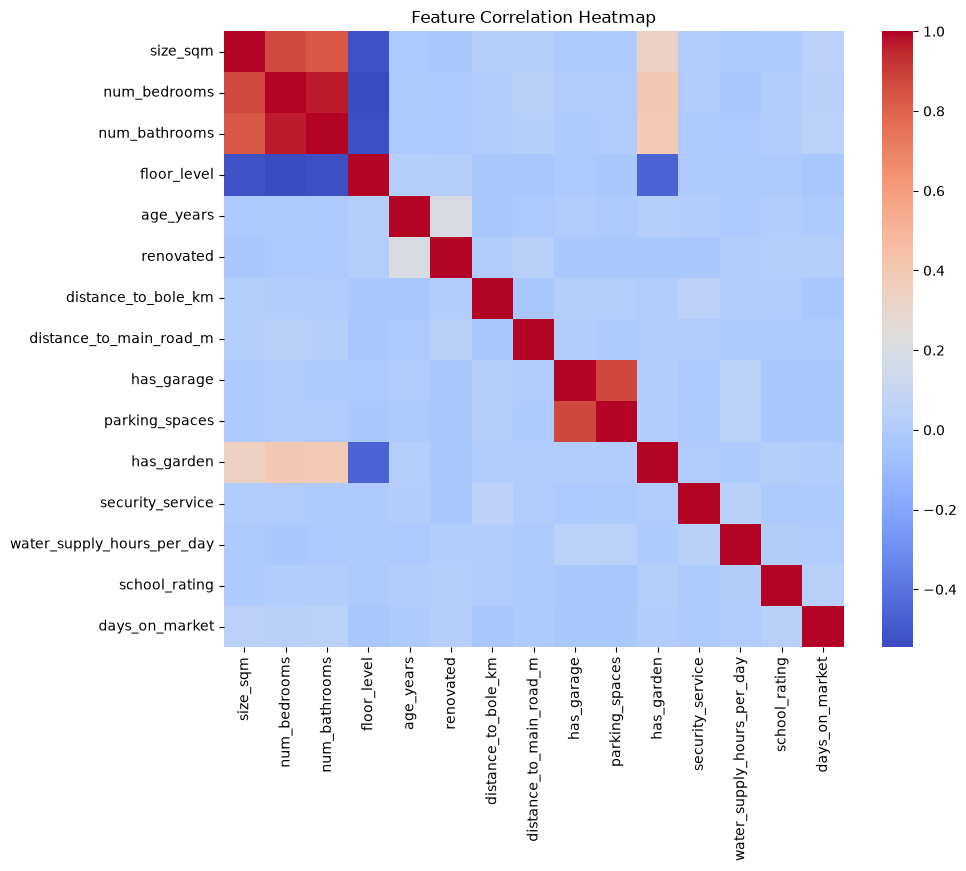

In [11]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    X_imputed.corr(),
    annot=False,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()